# Staffing Boston's 311 City Service Teams

IE 5374 Applied Generative AI, Module 7 Hackathon, Topic 2.

We plan how many field crews four City of Boston departments need in each month of 2025, using the
real 311 requests from 2023 and 2024, and we build a 311 intake assistant that turns a resident's
message into the right request type, department and queue.

| Code | Department |
|---|---|
| PWDx | Public Works |
| BTDT | Transportation |
| PARK | Parks and Recreation |
| ISD | Inspectional Services |

The request data is real. Crew capacities, costs and starting crews are the planning assumptions
from the brief, all read from `config.yaml`.

**AI use.** We used AI tools while building this project; every use is listed in
`docs/ai_use_log.md`. Sections whose content was generated by an LLM are marked *AI-generated*.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import data, forecast, equity

%matplotlib inline
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

## 1. Data

Both years come straight from the raw CSV files in `data/raw/`. The files are large (about 175 MB
each), so we read them with DuckDB and keep only the four departments before doing anything else.
Timestamps stay in local Boston time. 2025 data is not used, because the city changed 311 systems
in October 2025.

In [2]:
con = data.duckdb.connect()
raw = data.load_requests(con)
data.counts_by_year(raw).pivot(index="department", columns="year", values="requests")

year,2023,2024
department,,
BTDT,75314,81447
ISD,18123,18624
PARK,17541,18736
PWDx,171268,157610


### Check against the brief

The 2024 request counts and on-time shares should match the brief: 157,610 / 81,447 / 18,736 /
18,624 requests and 90% / 50% / 93% / 72% on time.

In [3]:
check = data.check_2024(raw)
check["brief_requests"] = check.department.map({"PWDx": 157610, "BTDT": 81447, "PARK": 18736, "ISD": 18624})
check["brief_on_time_pct"] = check.department.map({"PWDx": 90, "BTDT": 50, "PARK": 93, "ISD": 72})
check

,department,requests,on_time_pct,on_time_pct_with_target,no_target,brief_requests,brief_on_time_pct
0,BTDT,81447,49.9,48.9,1600,81447,50
1,ISD,18624,72.4,72.3,67,18624,72
2,PARK,18736,93.2,93.0,415,18736,93
3,PWDx,157610,89.7,87.3,29339,157610,90


Counts match exactly, and the on-time shares match when **every** request is counted. Requests
with no target date are all marked ONTIME in the data; leaving them out would drop Public Works to
87%, so we count all requests the same way the brief does.

### Cleaned file

`requests_clean.parquet` holds one row per request with the team's column names, plus helper
columns `year, month, has_target, days_to_close, source_group`. Every request is counted as
workload, whatever its closure reason. `case_title` has HTML codes decoded and whitespace trimmed.

In [4]:
if not data.CLEAN_FILE.exists():
    data.build_clean_file()
df = data.load_clean()
print(f"{len(df):,} rows, {df.shape[1]} columns")
df.isna().sum().rename("missing").to_frame().T

558,663 rows, 16 columns


,id,opened,target,closed,department,type,queue,case_title,neighborhood,source,on_time,year,month,has_target,days_to_close,source_group
missing,0,0,82143,51814,0,0,0,0,4046,0,0,0,0,0,51814,2


In [5]:
no_target = (~df.has_target).groupby(df.year).mean().mul(100).round(1)
print("Share of requests with no target date (%):")
no_target

Share of requests with no target date (%):


year
2023    18.0
2024    11.4
Name: has_target, dtype: float64

About 11% of 2024 requests in our four departments have no target date (16% across every
department in the file, which is the brief's figure). Many Parks requests have a 365-day target,
and 42% of all requests were logged by city employees rather than residents (Section 6 looks at
this).

## 2. Forecast

### Monthly demand, 2023-2024

In [6]:
demand = forecast.monthly_demand(df)
demand.pivot_table(index="month", columns=["department", "year"], values="requests")

department    BTDT             ISD            PARK             PWDx         
year          2023    2024    2023    2024    2023    2024     2023     2024
month                                                                       
1           5692.0  5620.0  1307.0  1491.0   765.0   928.0  12843.0  13582.0
2           5316.0  5954.0  1793.0  1285.0   651.0   794.0   9978.0  11550.0
3           6889.0  7209.0  1240.0  1342.0   911.0  1291.0  12402.0  13092.0
4           6143.0  7008.0  1201.0  1415.0  1206.0  1519.0  12985.0  13998.0
5           6737.0  7511.0  1386.0  1555.0  2095.0  2029.0  15267.0  13333.0
6           6682.0  7176.0  1723.0  1779.0  2313.0  2881.0  14947.0  12917.0
7           5517.0  6678.0  1587.0  1796.0  2299.0  2640.0  16188.0  13915.0
8           6473.0  6719.0  1723.0  2077.0  2382.0  2143.0  20224.0  16398.0
9           7190.0  7633.0  1678.0  1809.0  1532.0  1587.0  18578.0  15912.0
10          7018.0  7675.0  1597.0  1610.0  1366.0  1153.0  14113.0  11639.0
11          5964.0  6606.0  1537.0  1215.0   810.0   935.0  11813.0  10172.0
12          5693.0  5658.0  1351.0  1250.0  1211.0   836.0  11930.0  11102.0

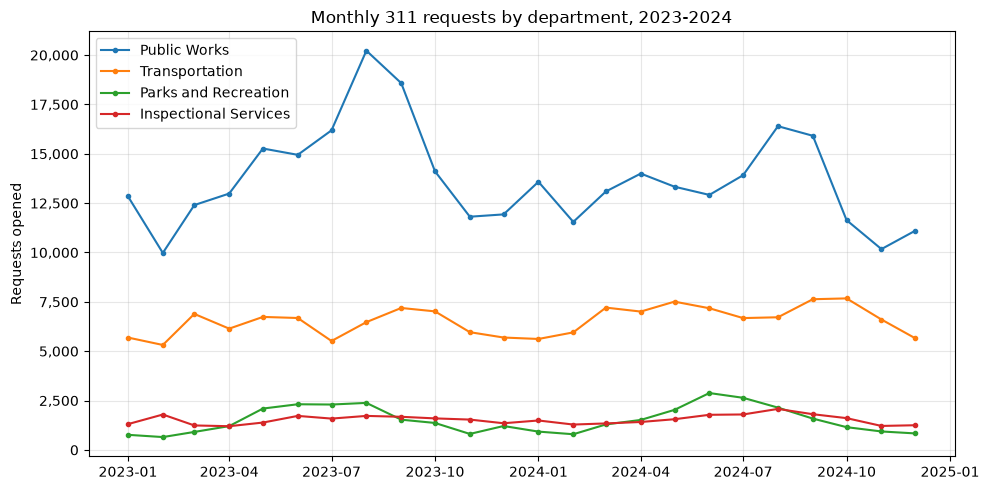

In [7]:
forecast.plot_monthly_demand(demand);

Public Works peaks in August-September, and Parks more than triples from January to June, as the
brief describes. Public Works also fell about 8% from 2023 to 2024, while the other three
departments grew 3-8%.

### 2025 forecast

With only 24 monthly points per department, a fitted time-series model would not be reliable, so we
use a simple seasonal method:

- **seasonal share** = each month's share of its year's requests, averaged over 2023 and 2024
- **2025 annual total** = 2024 total x (2024 total / 2023 total), carrying the 2023-to-2024 growth
  rate one more year
- **forecast** = seasonal share x 2025 annual total

There are no low/high ranges here; the +/-20% demand scenarios in the sensitivity section cover
uncertainty.

In [8]:
fc = forecast.forecast_2025(demand)
table = fc.pivot(index="month", columns="department", values="forecast")[data.DEPTS]
table.loc["Total"] = table.sum()
table

department,PWDx,BTDT,PARK,ISD
month,,,,
1,11688,6367,932,1456
2,9539,6328,795,1607
3,11275,7926,1209,1344
4,11939,7381,1499,1361
5,12599,8001,2279,1531
6,12273,7787,2858,1824
7,13257,6837,2721,1761
8,16109,7418,2503,1977
9,15188,8332,1721,1816


In [9]:
totals = forecast.annual_totals(demand)
totals["growth_%"] = ((totals[2024] / totals[2023] - 1) * 100).round(1)
totals["forecast_2025"] = fc.groupby("department").forecast.sum()
totals.loc[data.DEPTS]

year,2023,2024,growth_%,forecast_2025
department,,,,
PWDx,171268,157610,-8.0,145040
BTDT,75314,81447,8.1,88078
PARK,17541,18736,6.8,20010
ISD,18123,18624,2.8,19140


**Checking the method.** We forecast 2024 from 2023 alone (2023's monthly pattern at 2023's total)
and compare with what actually happened. MAPE is the average monthly error.

In [10]:
forecast.backtest_2024(demand)

,department,MAPE %
0,PWDx,13.6
1,BTDT,7.6
2,PARK,17.7
3,ISD,13.3


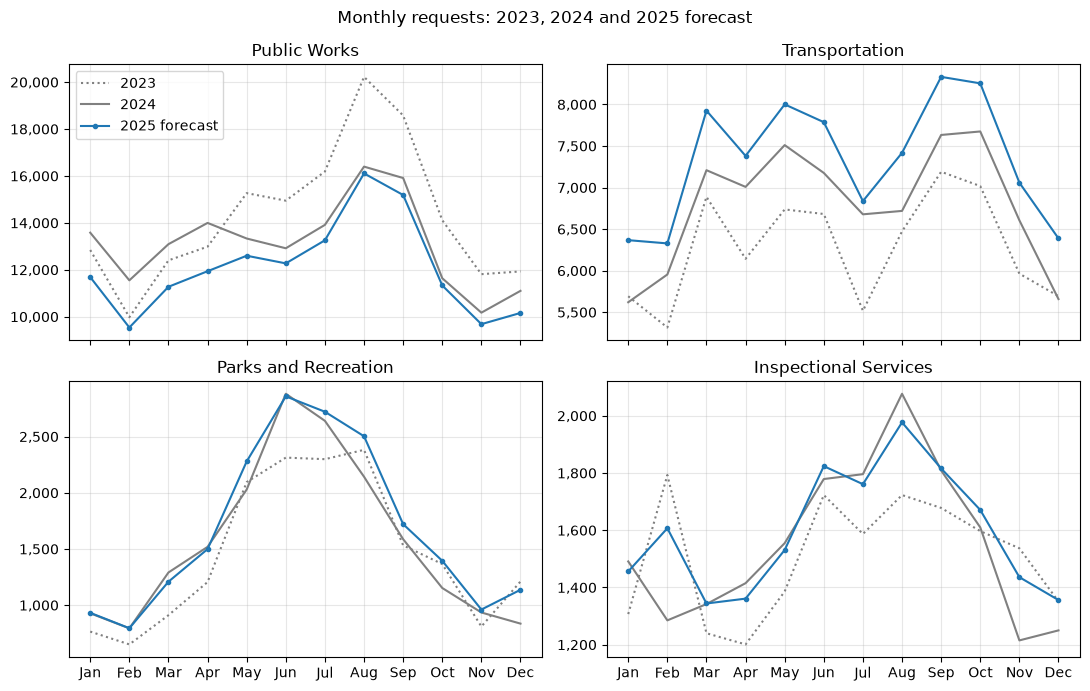

In [11]:
forecast.plot_forecast(demand, fc);

Transportation is the most predictable (about 8% error). Parks has the largest error because its
2024 peak came in June instead of August. The Public Works error is mostly the 8% drop in its
annual total, which a one-year backtest cannot see. The 2025 forecast carries that drop forward,
so Public Works is the forecast to watch most closely.

## 3. Intake Assistant

*Person B: intake assistant and Streamlit app go here (`src/intake.py`, `app/`).*

### Request-type catalog (AI-generated descriptions)

The assistant picks from all 170 request types in the 2024 data. For each type the catalog holds
its most common department, its queues with their shares, the 2024 count, a one-sentence
plain-language description and up to five example titles.

The descriptions and cleaned titles are **AI-generated** by `gpt-4o-mini` (temperature 0,
structured output). Every response is cached in `data/cache/llm/`, so this notebook makes no API
calls and gives the same result every run. Example titles are checked in code against the real
titles, so the model cannot invent them.

In [12]:
catalog = json.loads((ROOT / "data/processed/type_catalog.json").read_text())
print(f"{len(catalog)} request types")
cat = pd.DataFrame(catalog)
cat["top_queue"] = cat.queues.map(lambda q: q[0]["queue"])
cat[["type", "department", "n_2024", "top_queue", "description"]].head(15)

170 request types


,type,department,n_2024,top_queue,description
0,Parking Enforcement,BTDT,63112,BTDT_Parking Enforcement,There is an issue with parking regulations bei...
1,Requests for Street Cleaning,PWDx,22507,PWDx_District 1C: Downtown,The street is dirty and needs to be cleaned.
2,Improper Storage of Trash (Barrels),PWDx,20460,PWDx_Code Enforcement,Trash barrels are not stored properly and are ...
3,CE Collection,PWDx,18131,PWDx_District 1C: Downtown,There is debris or litter that needs to be col...
4,Schedule a Bulk Item Pickup,PWDx,11829,PWDx_Schedule a Bulk Item Pickup,I need to schedule a pickup for large items I ...
5,Needle Pickup,GEN,10736,GEN_Needle_Pickup,There are needles on the ground that need to b...
6,Request for Pothole Repair,PWDx,10620,PWDx_Roadway Repair_ARP_Resurfacing,There is a pothole on the road that needs to b...
7,Missed Trash/Recycling/Yard Waste/Bulk Item,PWDx,10593,PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item,My trash or recycling was not picked up on the...
8,Poor Conditions of Property,PWDx,8776,PWDx_Code Enforcement,The property is in bad shape and needs attention.
9,Tree Maintenance Requests,PARK,8618,PARK_Tree Maintenance Request,There are issues with the trees that need main...


## 4. Staffing Plan

*Person C: staffing model and monthly crew plan go here (`src/simulator.py`, `src/planner.py`),
using `data/processed/forecast_2025.csv`.*

## 5. Sensitivity

*Person C: base, high (+20%), low (-20%), snowstorm and heat-wave scenarios go here
(`src/reporter.py`).*

## 6. Other Considerations

Both tables below use 2024. On-time % counts every request, as in Section 1. Median days to close
only uses requests that were closed.

### Neighborhoods

Only neighborhoods with at least 100 requests in a department are shown. A few areas appear under
two names in the data (for example "South Boston" and "South Boston / South Boston Waterfront");
these are merged. "Boston" is the city's label when no specific neighborhood was recorded.

In [13]:
nb = equity.neighborhood_table(df)
nb[nb.department.isin(["BTDT", "PWDx"])].sort_values(["department", "on_time_pct"])

,department,neighborhood,requests,on_time_pct,median_days_to_close
0,BTDT,West Roxbury,1678,36.5,4.2
1,BTDT,Jamaica Plain,5566,39.2,3.0
2,BTDT,Hyde Park,2027,39.4,4.3
3,BTDT,Roslindale,2736,42.5,3.0
4,BTDT,Charlestown,3541,42.6,1.5
5,BTDT,Greater Mattapan,2049,44.6,3.5
6,BTDT,Roxbury,5284,45.3,2.0
7,BTDT,East Boston,6328,45.5,1.2
8,BTDT,Mission Hill,1100,47.1,1.1
9,BTDT,South End,4517,47.7,0.9


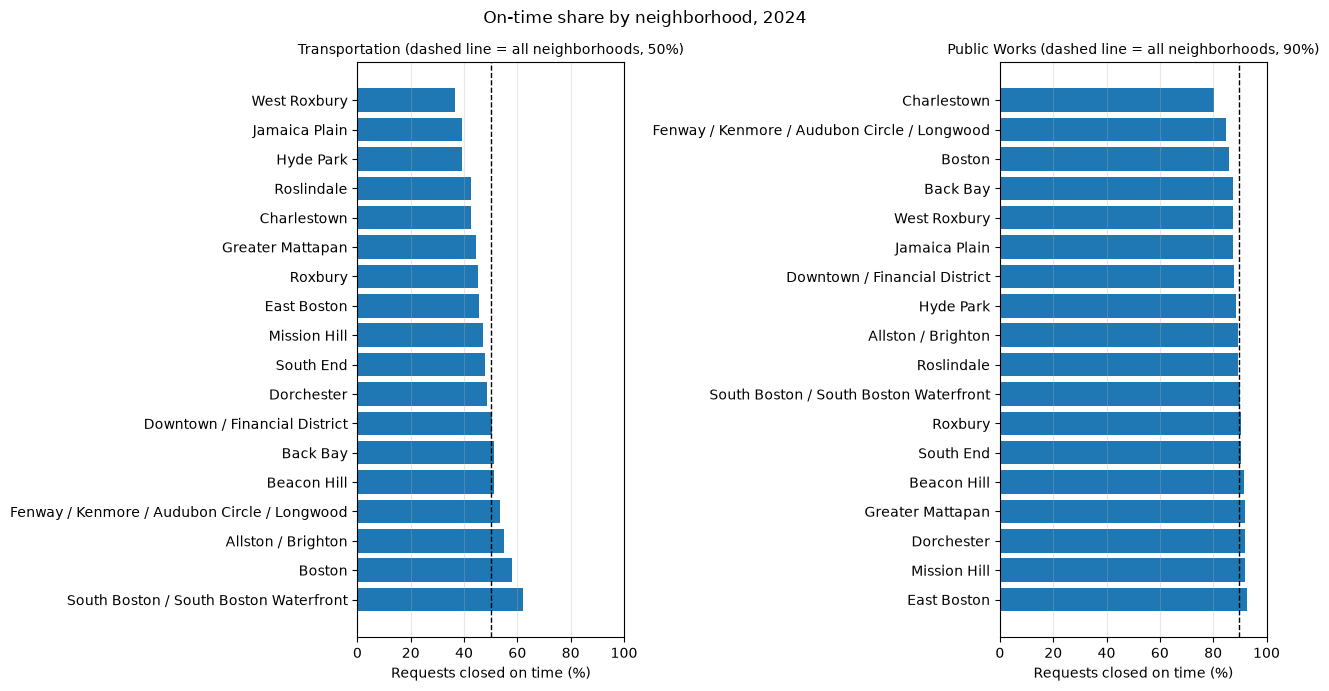

In [14]:
equity.plot_neighborhoods(nb);

**Finding (draft).** Service quality differs most by neighborhood in Transportation: only about
37-39% of requests in West Roxbury, Jamaica Plain and Hyde Park closed on time, compared with 62% in
South Boston, and the outer neighborhoods also waited longest (median 3-4 days vs. under 1 day
downtown). Public Works is more even (80-93% on time), though Charlestown trails the rest by about
7 points. In Inspectional Services, Greater Mattapan and East Boston have the lowest on-time rates
(about 64%).

### Employee vs. resident requests

**Employee** = Employee Generated and City Worker App. **Resident** = Citizens Connect App,
Constituent Call and Self Service.

In [15]:
equity.source_group_table(df)

,department,source_group,requests,share_pct,on_time_pct,median_days_to_close
0,BTDT,Employee,50182,61.6,50.1,0.9
1,BTDT,Resident,31265,38.4,49.7,1.6
2,ISD,Employee,7502,40.3,74.7,2.2
3,ISD,Resident,11122,59.7,70.9,3.2
4,PARK,Employee,11307,60.3,95.0,2.8
5,PARK,Resident,7429,39.7,90.4,1.9
6,PWDx,Employee,78174,49.6,89.6,0.1
7,PWDx,Resident,79436,50.4,89.8,0.5


**Finding (draft).** City employees log more than half of the requests in Transportation (62%) and
Parks (60%), so a large part of crew workload comes from staff spotting problems themselves rather
than from resident complaints. Resident requests are closed on time slightly less often in Parks
(90% vs. 95%) and Inspectional Services (71% vs. 75%), and usually take longer to close. In Public
Works, 32% of resident requests have no target date (and so count as on time) compared with 5% of
employee requests, so the near-equal on-time rates there may hide a gap.